# Volumetric Imaging: 2D Multislice and 3D

**Part:** H – Imaging methods · **Reading time:** ~50 min · **Pass 1 overview:** [From Signal to Image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) and [Contrast and Image Quality](../pass1_big_picture/P1.4_Contrast_and_Image_Quality.ipynb) · **Refreshers you may want:** [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb), [2D Fourier & images](../refreshers/RM6_2D_Fourier_and_Images.ipynb)

**Volumetric imaging** means acquiring images that cover a whole volume (a head, a knee, a liver), not just one slice. So far we have built a single 2D slice: slice selection ([E2](../pass2_deep_dive/E2_Slice_Selection.ipynb)) plus frequency and phase encoding ([F1](../pass2_deep_dive/F1_Spatial_Encoding.ipynb), [F2](../pass2_deep_dive/F2_K-space.ipynb)). This chapter covers the two ways to extend that to a volume: **2D multislice imaging** (many thin slices, acquired interleaved) and **3D imaging** (a thick slab, with a second phase-encoding direction). Nearly every clinical protocol is a mix of the two. Choosing between them sets the scan time, the contrast you can get, the SNR, and whether the data can be **reformatted** into any viewing plane.

## Learning goals

1. Describe how images are formed
    * Describe how 2D multislice imaging works (RF frequency offsets, interleaving within TR)
    * Describe how 3D imaging works (slab excitation, second phase-encoding direction $k_z$)
1. Understand the constraints and trade-offs in MRI
    * Work out how many slices fit into one TR, and what happens to scan time when they don't
    * Explain slice cross-talk and why slice gaps or sharper RF pulses reduce it
    * Determine which contrasts suit 2D multislice and which suit 3D imaging
    * Derive how SNR changes between 2D multislice and 3D imaging (the $\sqrt{N_z}$ factor) and why the advantage is partly offset by T1 recovery
    * Understand when 2D multislice or 3D imaging is preferred, and what isotropic resolution and reformatting give you
1. Manipulate and analyze MRI data
    * Simulate slice profiles, cross-talk, slab aliasing in $z$, the 3D SNR gain, and reformatting

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $x, y, z$ | position: readout, phase-encode and slice / second phase-encode direction | m | $z$ = slice direction here (along $B_0$ for axial slices) |
| $B_0$ | main static field | T | 1.5 T, 3 T |
| $\bar\gamma$ | gyromagnetic ratio ("gamma-bar") | Hz/T | 42.58 MHz/T for ¹H |
| $\gamma$ | angular gyromagnetic ratio $=2\pi\bar\gamma$ | rad s⁻¹ T⁻¹ | $2.675\times10^8$ |
| $G_{z,SS}$ | slice-select gradient amplitude | T/m | 5–30 mT/m |
| $G_z(t)$ | gradient along $z$ (in 3D: also the second phase-encoding gradient) | T/m | |
| $\Delta z$ | slice thickness (2D) | m | 1–10 mm |
| $d_{gap}$ | gap between adjacent slices (edge to edge) | m | 0–100 % of $\Delta z$ (often 10–20 %) |
| $z_{off}$ | position of a slice centre | m | |
| $f_{off}$ | RF frequency offset that selects the slice at $z_{off}$ | Hz | kHz range |
| $T_{rf}$, $BW_{rf}$, $TBW$ | RF pulse duration, bandwidth, time–bandwidth product | s, Hz, – | 2 ms, 2 kHz, 2–12 |
| $\theta$, $\theta(z)$ | flip angle; flip angle actually reached at position $z$ (the slice profile) | rad (°) | |
| $TR$, $TE$ | repetition time, echo time | s | |
| $T_{slice}$ | time one slice occupies inside each TR (excitation → end of readout and spoilers); the original calls it $T_{active}$ | s | 5–40 ms |
| $N_{slices}$, $N_{slices,max}$ | number of slices requested; maximum number that fits into one TR | – | |
| $N_{acq}$ | number of separate "packages"/"concatenations" needed when $N_{slices}>N_{slices,max}$ | – | 1–3 |
| $N_x$, $N_{read}$ | readout samples per line | – | 256 |
| $N_{PE}$, $N_y$ ($=N_{PE,1}$) | phase-encoding lines (in-plane) | – | 128–512 |
| $N_z$ ($=N_{PE,2}$) | number of partitions = second phase-encode steps in 3D | – | 32–256 |
| $NEX$ ($=N_{avg}$) | number of averages | – | 1–4 |
| $N_{TR}$ | number of TRs needed for one image (or volume) | – | |
| $T_{scan}$ | total scan time | s | minutes |
| $\Delta t$, $T_{read}$ | dwell time, readout duration ($=N_x\Delta t$) | s | 4 µs, 4 ms |
| $T_{meas}$ | total time the ADC samples data that contribute to a voxel | s | |
| $k_z$, $\Delta k_z$ | k-space coordinate along $z$ and its step | m⁻¹ | |
| $FOV_z$, $\delta_z$ | field of view and resolution along $z$ ($FOV_z=1/\Delta k_z$, $\delta_z = FOV_z/N_z$) | m | 0.1–0.2 m, 1 mm |
| $\delta_x,\delta_y$ | in-plane pixel size | m | 0.5–1 mm |
| $V_{voxel}=\delta_x\delta_y\delta_z$ | voxel volume | m³ | 1 mm³ $=10^{-9}$ m³ |
| $SNR$, $\sigma_n$ | signal-to-noise ratio; noise standard deviation per sample | –, a.u. | |
| $f_{seq}$ | sequence/contrast factor: fraction of $M_0$ that is in the transverse plane at TE | – | 0–1, from signal equations |
| $T_1$, $E_1=e^{-\tau/T_1}$ | longitudinal relaxation time; recovery factor over a time $\tau$ | s, – | WM ≈ 0.6–0.8 s |
| $M_z$ | longitudinal magnetization (normalized, $M_0=1$) | – | |
| $m(\vec r)$, $M(\vec k)$ | image (transverse magnetization), its k-space data (Larson's $M$, **not** magnetization) | a.u. | |

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. Three ways to cover a volume

Suppose you want 30 axial slices through a head. You could:

1. **Repeat a single-slice scan 30 times** (sequential). Simple, but wasteful: most of each TR is spent waiting for T1 recovery.
2. **2D multislice, interleaved**: while slice 1 is recovering, excite and read out slices 2, 3, …, i.e. use the dead time inside each TR. This is the standard way 2D imaging is done.
3. **3D imaging**: excite one thick slab and *also* phase-encode along $z$. The image is then a 3D Fourier transform of 3D k-space.

The rest of this chapter makes each option quantitative.

> **🧭 Intuition:** In 2D multislice, the $z$ position is decided by *which spins you excite* (selective RF). In 3D imaging, the $z$ position is decided by *encoding* (a phase ramp along $z$), exactly like $y$ is decided by phase encoding. Everything else follows from this difference.

## 2. 2D multislice imaging

A single-slice sequence extends easily to multiple slices. The *identical* sequence is used; only the centre frequency of the RF pulse changes to move the slice. With a slice-select gradient $G_{z,SS}$ switched on, the Larmor frequency in the rotating frame depends on $z$, so a pulse with frequency offset $f_{off}$ excites the slice centred where the spins resonate at $f_{off}$ (see [Slice Selection](../pass2_deep_dive/E2_Slice_Selection.ipynb)):

$$f_{off} = \bar\gamma\, G_{z,SS}\, z_{off}.$$

In words: the RF frequency offset needed to excite a slice is "how fast the frequency changes per metre" ($\bar\gamma G_{z,SS}$, in Hz/m) times "how far the slice is from the isocentre" ($z_{off}$),

where $\bar\gamma = 42.58$ MHz/T, $G_{z,SS}$ [T/m] is the slice-select gradient and $z_{off}$ [m] is the slice-centre position.

The slice thickness follows from the pulse bandwidth: $\Delta z = BW_{rf}/(\bar\gamma G_{z,SS})$, so all slices of a stack use the same pulse shape and the same gradient, and differ only in $f_{off}$ (and the receiver demodulation phase).

In [2]:
# RF frequency offsets for a stack of 2D slices
G_ss = 10e-3            # slice-select gradient [T/m] (10 mT/m)
dz = 5e-3               # slice thickness [m]
gap = 1e-3              # gap between slices [m] (20 % of dz)
n_slices = 9

z_off = (np.arange(n_slices) - (n_slices - 1) / 2) * (dz + gap)   # slice centres [m]
f_off = mt.GAMMA_BAR * G_ss * z_off                                 # [Hz]
T_rf = 2e-3                                                         # pulse duration [s]
BW_rf = mt.GAMMA_BAR * G_ss * dz                                    # bandwidth needed for dz [Hz]

print(f"Frequency change per mm: {mt.GAMMA_BAR*G_ss*1e-3:.0f} Hz/mm")
print(f"RF bandwidth for {dz*1e3:.0f} mm slices: {BW_rf:.0f} Hz  -> TBW = {BW_rf*T_rf:.1f} for a {T_rf*1e3:.0f} ms pulse")
for z, f in zip(z_off, f_off):
    print(f"  slice at z = {z*1e3:+6.1f} mm  ->  f_off = {f/1e3:+7.2f} kHz")

Frequency change per mm: 426 Hz/mm
RF bandwidth for 5 mm slices: 2129 Hz  -> TBW = 4.3 for a 2 ms pulse
  slice at z =  -24.0 mm  ->  f_off =  -10.22 kHz
  slice at z =  -18.0 mm  ->  f_off =   -7.66 kHz
  slice at z =  -12.0 mm  ->  f_off =   -5.11 kHz
  slice at z =   -6.0 mm  ->  f_off =   -2.55 kHz
  slice at z =   +0.0 mm  ->  f_off =   +0.00 kHz
  slice at z =   +6.0 mm  ->  f_off =   +2.55 kHz
  slice at z =  +12.0 mm  ->  f_off =   +5.11 kHz
  slice at z =  +18.0 mm  ->  f_off =   +7.66 kHz
  slice at z =  +24.0 mm  ->  f_off =  +10.22 kHz


The offsets are a few kHz to tens of kHz, tiny compared with the Larmor frequency (127.7 MHz at 3 T), and trivial for a modern digital RF synthesizer to switch between pulses.

### 2.1 Interleaving

2D multislice is typically done in an **interleaved** fashion: the acquisitions for different slices go on "at the same time", in the sense that within one TR of slice 1 we also excite and read slices 2, 3, …. This works because there is usually a lot of spare time inside each TR. An example of interleaving:

![Interleaving illustration: within one TR, slices 1, 2, 3 are each excited (RF at different f_off) and read out (DAQ). The next TR repeats this with the next phase-encode step ("Encode 2").](../images/volumetric_imaging-2D_multislice.png)

*Each slice is excited once per TR with its own frequency $f_{off,i}$, and always with the same phase-encode step within a given TR block ("Encode 1, 2, 3").*

Note that **the TR of each slice is measured from one excitation of that slice to its next excitation**. That interval controls its T1 recovery and therefore its contrast; the other slices in between don't change it (as long as their pulses don't touch this slice, see cross-talk below).

### 2.2 How many slices fit into one TR?

Each slice needs a certain time $T_{slice}$ inside the TR: RF pulse, slice-select refocusing, phase encoding, readout (for a spin echo: the whole 90°–180°–echo block), and spoilers. The maximum number of interleaved slices is therefore

$$N_{slices,max} = \left\lfloor \frac{TR}{T_{slice}} \right\rfloor.$$

In words: you can fit as many slices as there are "slice slots" of duration $T_{slice}$ in one TR (rounded down, $\lfloor\cdot\rfloor$),

where $TR$ [s] is the repetition time and $T_{slice}$ [s] is the time each slice needs per TR. For a spin echo, roughly $T_{slice} \approx TE + T_{read}/2 + $ a few ms (pulses and spoilers).

If you ask for more slices than fit ($N_{slices} > N_{slices,max}$), the scanner splits them into $N_{acq} = \lceil N_{slices}/N_{slices,max}\rceil$ separate packages ("acquisitions", "concatenations"), run one after another. For fully sampled Cartesian encoding the scan time is

$$T_{scan,2D} = TR \; N_{PE}\; NEX \; N_{acq}.$$

In words: one TR per phase-encode line, repeated for each average, and repeated again for each package of slices,

where $N_{PE}$ is the number of phase-encode lines, $NEX$ (the original's $N_{avg}$) the number of averages, $N_{acq}$ the number of packages. When everything fits ($N_{acq}=1$), **the slices are free**: 1 slice or 30 slices take the same time.

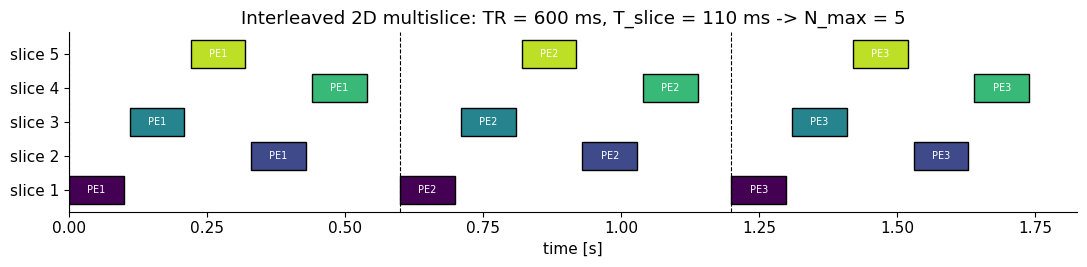

In [3]:
# Time-line of interleaved multislice acquisition (exaggerated timing so it is readable)
TR = 600e-3          # [s]
T_slice = 110e-3     # [s] time occupied by each slice
n_sl = 5
order = [0, 2, 4, 1, 3]      # interleaved slice ORDER: odd slices first, then even (see 2.4)
colors = plt.cm.viridis(np.linspace(0, 0.9, n_sl))

fig, ax = plt.subplots(figsize=(11, 2.8))
for tr in range(3):                         # three TRs = three phase-encode steps
    for slot, s in enumerate(order):
        t0 = tr * TR + slot * T_slice
        ax.barh(s, T_slice * 0.9, left=t0, color=colors[s], edgecolor="k")
        ax.text(t0 + T_slice * 0.45, s, f"PE{tr+1}", ha="center", va="center", fontsize=7, color="w")
    ax.axvline(tr * TR, color="k", lw=0.8, ls="--")
ax.set_yticks(range(n_sl)); ax.set_yticklabels([f"slice {s+1}" for s in range(n_sl)])
ax.set_xlabel("time [s]"); ax.set_title(f"Interleaved 2D multislice: TR = {TR*1e3:.0f} ms, "
                                         f"T_slice = {T_slice*1e3:.0f} ms -> N_max = {int(TR//T_slice)}")
ax.grid(False); plt.tight_layout(); plt.show()

Each row is one slice; it is visited exactly once per TR (dashed lines), so its own TR is still 600 ms. The idle time after the last slot is the leftover $TR - N_{slices}T_{slice}$.

Now realistic numbers for three common protocols:

In [4]:
# Realistic numbers: how many slices fit, and what does it cost?
protocols = [  # name, TR [s], T_slice [s], N_PE, NEX, requested slices
    ("T1w spin echo",           0.50,  0.018, 256, 1, 24),
    ("T2w spin echo (conventional)", 4.0, 0.110, 256, 1, 30),
    ("spoiled GRE, short TR",   0.010, 0.008, 256, 1, 30),
]
print(f"{'protocol':32s} {'N_max':>6s} {'N_acq':>6s} {'T_scan':>10s}")
for name, TR_, Ts, Npe, nex, nsl in protocols:
    n_max = int(TR_ // Ts)
    n_acq = int(np.ceil(nsl / n_max))
    T_scan = TR_ * Npe * nex * n_acq
    print(f"{name:32s} {n_max:6d} {n_acq:6d} {T_scan/60:8.1f} min")

protocol                          N_max  N_acq     T_scan
T1w spin echo                        27      1      2.1 min
T2w spin echo (conventional)         36      1     17.1 min
spoiled GRE, short TR                 1     30      1.3 min


* **Long TR (T2/PD weighting):** even with a long time per spin-echo slice (110 ms), 36 slices fit, i.e. the whole brain comes "for free" with the long TR the contrast needs anyway. This is why 2D multislice is the classic home of T2- and PD-weighted imaging (the 17 min scan time is the problem; fast spin echo in [H2](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb) fixes it).
* **Short TR (T1-weighted spin echo):** ~27 slices fit, enough for one package.
* **Very short TR (fast gradient echo, TR ≈ 10 ms):** only one slice fits. Interleaving gives nothing, and 30 slices take 30× longer. Such sequences are much better done in **3D** (section 4).

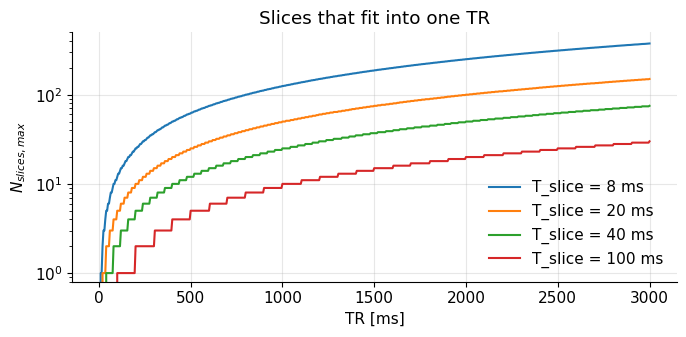

In [5]:
# N_slices,max versus TR for different per-slice times
TRs = np.linspace(5e-3, 3.0, 600)
fig, ax = plt.subplots(figsize=(7, 3.5))
for Ts in [8e-3, 20e-3, 40e-3, 100e-3]:
    ax.plot(TRs * 1e3, np.floor(TRs / Ts), label=f"T_slice = {Ts*1e3:.0f} ms")
ax.set_xlabel("TR [ms]"); ax.set_ylabel(r"$N_{slices,max}$"); ax.set_yscale("log")
ax.set_ylim(0.8, 500); ax.legend(); ax.set_title("Slices that fit into one TR")
plt.tight_layout(); plt.show()

The number of slices grows linearly with TR. On the log axis you can read off the "one-slice" limit: whenever $TR < T_{slice}$ only a single slice fits.

> **🔧 Engineering reality:** Interleaving many slices is not free for the hardware. Every slice adds RF pulses (more **SAR**, see [MRI Safety](../pass2_deep_dive/B6_MRI_Safety.ipynb)) and gradient pulses (more heating of the gradient coil and amplifier, see [Gradient System Engineering](../pass2_deep_dive/B4_Gradient_System_Engineering.ipynb)). Fast spin-echo protocols with many refocusing pulses are often limited by SAR at 3 T, not by time; the scanner then reduces the number of slices per TR or lengthens TR automatically.

### 2.3 Cross-talk from imperfect slice profiles

**Cross-talk** occurs because real RF pulses do not have perfectly rectangular slice profiles. The flip angle falls off gradually at the slice edges and has small side lobes outside. If slices are placed immediately next to each other, the pulse for slice $i+1$ partially excites (or saturates) the edge of slice $i$. That edge then has less longitudinal magnetization $M_z$ when its own pulse arrives: less signal, and altered contrast (effectively a shorter TR at the edges).

Two cures:

1. **Sharper slice profiles**: use RF pulses with a higher time–bandwidth product $TBW$ (see [RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb), [RF Pulse Design](../pass2_deep_dive/E3_RF_Pulse_Design.ipynb)), at the cost of longer pulses or more RF power.
2. **Gaps** between slices (typically 10–30 % of $\Delta z$), at the cost of not covering the gaps.

Let's quantify both. We first compute the actual flip-angle profile $\theta(z)$ of a 90° Hann-windowed sinc pulse with a Bloch simulation (`mt.bloch_simulate`), for $TBW$ = 2, 4 and 8.

> **🔁 Refresher:** For small flip angles the slice profile is approximately the Fourier transform of the RF envelope (a sinc pulse gives a near-rect profile; truncating it adds ripples). See [Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb). At 90° this is only approximate, which is why we use the full Bloch equation here.

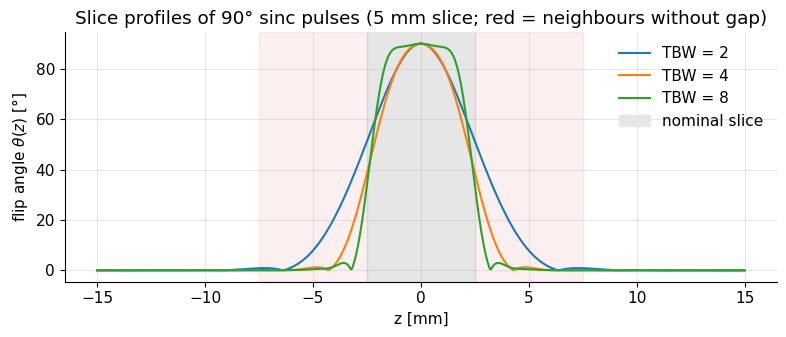

In [6]:
def slice_profile(TBW, T_rf=2e-3, dz=5e-3, theta=np.pi/2, z=None, dt=10e-6):
    """Flip-angle profile theta(z) [rad] of a Hann-windowed sinc pulse (Bloch simulation).

    TBW: time-bandwidth product; T_rf: pulse duration [s]; dz: slice thickness [m];
    theta: nominal flip angle [rad]. The slice-select gradient is chosen so that the
    pulse bandwidth BW_rf = TBW/T_rf covers exactly dz.
    """
    z = np.linspace(-15e-3, 15e-3, 601) if z is None else z
    n = int(round(T_rf / dt))
    tt = (np.arange(n) - n / 2 + 0.5) * dt                       # time axis centred on 0 [s]
    env = np.sinc(TBW * tt / T_rf) * (0.5 + 0.5 * np.cos(2 * np.pi * tt / T_rf))  # sinc x Hann window
    b1 = env / np.sum(env) * theta / (mt.GAMMA * dt)              # scale to nominal flip [T]
    G = (TBW / T_rf) / (mt.GAMMA_BAR * dz)                        # slice-select gradient [T/m]
    Gw = np.zeros((n, 3)); Gw[:, 2] = G
    r = np.zeros((len(z), 3)); r[:, 2] = z
    _, M = mt.bloch_simulate(B1=b1.astype(complex), dt=dt, G=Gw, r=r, return_all=False)
    # Mz after the pulse (starting from Mz = 1) gives the flip angle reached at each z
    return np.arccos(np.clip(M[:, 2], -1, 1))

z = np.linspace(-15e-3, 15e-3, 601)       # [m]
dz = 5e-3
profiles = {TBW: slice_profile(TBW, z=z, dz=dz) for TBW in (2, 4, 8)}

fig, ax = plt.subplots(figsize=(8, 3.5))
for TBW, th in profiles.items():
    ax.plot(z * 1e3, np.degrees(th), label=f"TBW = {TBW}")
ax.axvspan(-dz / 2 * 1e3, dz / 2 * 1e3, color="0.9", zorder=0, label="nominal slice")
for s in (-1, 1):   # neighbouring slices with zero gap
    ax.axvspan((s * dz - dz / 2) * 1e3, (s * dz + dz / 2) * 1e3, color="C3", alpha=0.07, zorder=0)
ax.set_xlabel("z [mm]"); ax.set_ylabel(r"flip angle $\theta(z)$ [°]")
ax.set_title("Slice profiles of 90° sinc pulses (5 mm slice; red = neighbours without gap)")
ax.legend(); plt.tight_layout(); plt.show()

The low-TBW pulse (2) leaks well into the neighbouring slices (red bands); TBW 8 is close to a rectangle. Now the effect on signal: a simple model of a **spoiled** sequence (transverse magnetization destroyed before every pulse) where, within each TR, each position $z$ of the slice of interest experiences

1. its own pulse, flip $\theta_0(z)$, at $t = 0$ (signal $\propto M_z^- \sin\theta_0(z)$, where $M_z^-$ is $M_z$ just before the pulse),
2. the two neighbours' pulses, flips $\theta_0(z\mp d)$ with centre spacing $d=\Delta z + d_{gap}$, at $t = TR/2$ (interleaved order puts neighbours roughly half a TR away),
3. T1 recovery in between: $M_z \to 1 + (M_z-1)E_1$ with $E_1 = e^{-\tau/T_1}$ over an interval $\tau$.

A pulse of flip $\theta$ multiplies $M_z$ by $\cos\theta$. We iterate until steady state and integrate the signal over $z$.

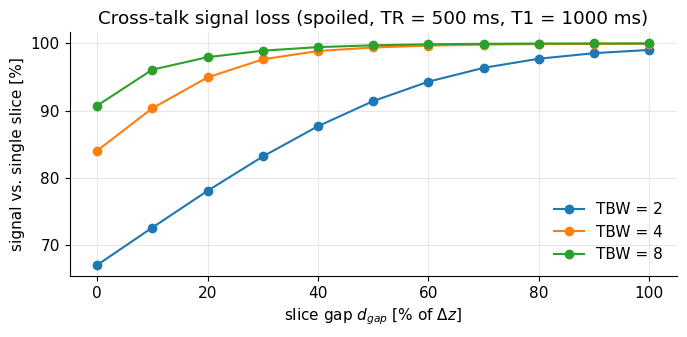

In [7]:
def crosstalk_signal(theta_of_z, z, d, TR, T1, neighbours=True, n_iter=60):
    """Steady-state slice signal (integrated over z) with/without neighbour pulses at TR/2.

    theta_of_z: function z -> flip angle [rad] of the slice centred at 0.
    d: centre-to-centre slice spacing [m]. Spoiled sequence: only Mz carries over.
    """
    th0 = theta_of_z(z)
    th_nb = theta_of_z(z - d), theta_of_z(z + d)
    E = np.exp(-(TR / 2) / T1)                        # recovery factor over half a TR
    Mz = np.ones_like(z)
    for _ in range(n_iter):
        sig = Mz * np.sin(th0)                         # signal per position from own pulse
        Mz = Mz * np.cos(th0)                          # own pulse
        Mz = 1 + (Mz - 1) * E                          # recover TR/2
        if neighbours:
            Mz = Mz * np.cos(th_nb[0]) * np.cos(th_nb[1])   # neighbour pulses (spoiled)
        Mz = 1 + (Mz - 1) * E                          # recover TR/2
    return np.trapezoid(sig, z) if hasattr(np, "trapezoid") else np.trapz(sig, z)

TR, T1 = 0.5, 1.0          # [s]  T1-weighted-ish protocol, gray-matter-like T1
gaps = np.linspace(0, 1.0, 11) * dz       # gap 0 ... 100 % of slice thickness [m]
z_wide = np.linspace(-25e-3, 25e-3, 1001)

fig, ax = plt.subplots(figsize=(7, 3.5))
for TBW in (2, 4, 8):
    th = slice_profile(TBW, z=z_wide, dz=dz)
    theta_fun = lambda zz, th=th: np.interp(zz, z_wide, th, left=0, right=0)
    ref = crosstalk_signal(theta_fun, z_wide, 1.0, TR, T1, neighbours=False)
    rel = [crosstalk_signal(theta_fun, z_wide, dz + g, TR, T1) / ref for g in gaps]
    ax.plot(gaps / dz * 100, np.array(rel) * 100, "o-", label=f"TBW = {TBW}")
ax.set_xlabel(r"slice gap $d_{gap}$ [% of $\Delta z$]"); ax.set_ylabel("signal vs. single slice [%]")
ax.set_title(f"Cross-talk signal loss (spoiled, TR = {TR*1e3:.0f} ms, T1 = {T1*1e3:.0f} ms)")
ax.legend(); plt.tight_layout(); plt.show()

With contiguous slices (0 % gap) the TBW-2 pulse loses about a third of the signal to cross-talk, TBW 4 about 15 %, and even TBW 8 still about 10 % (its transition band is narrower but not zero). A 20–30 % gap removes most of the loss for TBW ≥ 4. Cross-talk is worse for long-T1 tissue (less recovery between hits) and in spin-echo sequences, where the neighbours' 180° refocusing pulses (with their own imperfect profiles) also hit the slice.

### 2.4 Slice ordering

The *order* in which slices are excited within a TR matters for the same reason. **Sequential** order (1, 2, 3, …) excites the neighbour immediately after a slice, when its edge is most saturated. **Interleaved** order (1, 3, 5, …, 2, 4, 6, …) puts neighbours about $TR/2$ apart. In the extreme, scanners split odd and even slices into two separate packages ($N_{acq}=2$), so neighbours are never excited in the same TR at all, at twice the scan time.

> **⚠️ Common confusion:** "Gap" is defined edge-to-edge (as a distance or as % of slice thickness), not centre-to-centre. A 5 mm slice with a 1 mm gap ("20 %") has a centre spacing of 6 mm. And the nominal slice thickness is usually the full width at half maximum (FWHM) of the profile: some signal always comes from outside it.

> **🔧 Engineering reality:** Gaps are common in routine clinical 2D protocols (e.g. 4 mm slices with 1 mm gap in brain imaging). Small lesions can fall into a gap and be missed. That is one reason 3D acquisitions with contiguous thin partitions are increasingly preferred.

## 3. 3D imaging: phase encoding in the third dimension

True **3D imaging** resolves voxels in 3 dimensions with spatial encoding gradients. In Cartesian encoding this is done by adding a **second phase-encoding gradient** in what is normally the slice direction. A 3D volume of k-space is sampled:

$$k_x(t)=\bar\gamma\int_0^t G_x(\tau)d\tau,\quad k_y=\bar\gamma\, G_{y}\, t_y,\quad k_z=\bar\gamma\, G_{z}\, t_z.$$

In words: $k_x$ is swept during the readout as before; $k_y$ and $k_z$ are each set once per TR by the area (amplitude × duration) of a phase-encoding gradient pulse,

where $G_y$, $G_z$ [T/m] are the phase-encode amplitudes (stepped from TR to TR), $t_y$, $t_z$ [s] their durations and $\bar\gamma$ [Hz/T] the gyromagnetic ratio. The $z$ steps are called **partitions** (Siemens) or simply "slices" of the 3D slab.

An RF pulse can still be slice-selective, but with a much thicker slice (the whole volume, e.g. 160 mm). Such pulses are called **slab-selective**. Sometimes a **non-selective** (hard) RF pulse is used instead, relying on the limited extent of the RF receive-coil sensitivity (or of the anatomy) to limit the FOV in $z$. A 3D FT pulse sequence:

![3D FT pulse sequence: slab-selective RF + Gz, phase encoding on both Gy and Gz (two independent tables), readout on Gx.](../images/pulse_sequence-diagram-all-3D.png)

*Note the phase-encoding "table" now on both $G_y$ and $G_z$. Every combination of a $k_y$ step and a $k_z$ step needs its own TR (in a basic 3D sequence).*

The image is obtained by a **3D inverse Fourier transform** of the 3D k-space data $M(k_x,k_y,k_z)$. Because the 3D FT is separable, it is just three 1D FFTs, one along each axis (see [2D Fourier & images](../refreshers/RM6_2D_Fourier_and_Images.ipynb); 3D works the same way).

Now the number of TRs required is the **product** of the numbers of phase encodes in both directions:

$$N_{TR} = N_{y}\, N_{z}\, NEX, \qquad T_{scan,3D} = TR\, N_{y}\, N_{z}\, NEX .$$

In words: every ($k_y$, $k_z$) pair is one TR, so the scan time is TR × (in-plane phase encodes) × (partitions) × (averages),

where $N_y = N_{PE,1}$ and $N_z = N_{PE,2}$ in the original's notation. This is why 3D sequences must use short TRs.

In [8]:
# Scan time of 3D acquisitions: TR must be short!
cases = [  # name, TR [s], Ny, Nz
    ("3D spoiled GRE, 1 mm iso brain", 8e-3, 256, 176),
    ("3D spoiled GRE, TR = 25 ms",     25e-3, 256, 176),
    ("3D with spin-echo TR = 500 ms",  0.5,  256, 176),
]
for name, TR_, Ny, Nz in cases:
    T = TR_ * Ny * Nz
    print(f"{name:34s}: T_scan = {T:8.0f} s = {T/60:6.1f} min")

3D spoiled GRE, 1 mm iso brain    : T_scan =      360 s =    6.0 min
3D spoiled GRE, TR = 25 ms        : T_scan =     1126 s =   18.8 min
3D with spin-echo TR = 500 ms     : T_scan =    22528 s =  375.5 min


A 1 mm isotropic brain volume with TR = 8 ms takes 6 minutes; with a spin-echo TR it would take over 6 hours. In practice 3D spin-echo imaging only became practical with long echo trains (3D fast spin echo, e.g. SPACE/CUBE/VISTA, see [Fast Imaging Pulse Sequences](../pass2_deep_dive/H2_Fast_Imaging_Pulse_Sequences.ipynb)) and with acceleration ([Accelerated Imaging Methods](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)).

### 3.1 Resolution and FOV in $z$

Everything you learned for phase encoding in $y$ ([FOV and Resolution](../pass2_deep_dive/G1_FOV_and_Resolution.ipynb)) now applies to $z$:

$$FOV_z = \frac{1}{\Delta k_z}, \qquad \delta_z = \frac{FOV_z}{N_z} = \frac{1}{2k_{z,max}} .$$

In words: the step in $k_z$ sets how big a region along $z$ can be represented without aliasing; the largest $k_z$ reached sets how thin each partition is,

where $\Delta k_z$ [m⁻¹] is the step between partition encodes, $k_{z,max}$ [m⁻¹] the largest $k_z$, $N_z$ the number of partitions.

In 2D, the slice profile is set by the RF pulse (soft edges, cross-talk). In 3D, the partition profile is set by the **Fourier encoding**: it is a sinc-like point spread function, just like in-plane (see [Point Spread Function Analysis](../pass2_deep_dive/I1_Point_Spread_Function_Analysis.ipynb)). No cross-talk between partitions, and partitions can be much thinner (0.5–1 mm) than practical 2D slices (≥ 2 mm, limited by gradient strength and RF pulse duration).

### 3.2 Slab profile and aliasing in $z$

Phase encoding along $z$ means that anything excited **outside** $FOV_z$ aliases (wraps around) into the volume, exactly as in $y$. The slab-selective pulse is designed to excite approximately $FOV_z$, but its profile has soft edges. The edge partitions therefore (a) get a lower flip angle (less signal, different contrast) and (b) can receive wrapped signal from the opposite side. Scanners fix this with **slice oversampling**: acquire extra partitions (e.g. +10–20 %) and discard the edges.

Let's simulate it with a simple 3D head phantom. The phantom is defined on an extended $z$ grid; we multiply it by a slab profile, Fourier transform along $z$, keep only every other $k_z$ sample (that halves $FOV_z$, see [Fourier pairs & sampling](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)), and reconstruct.

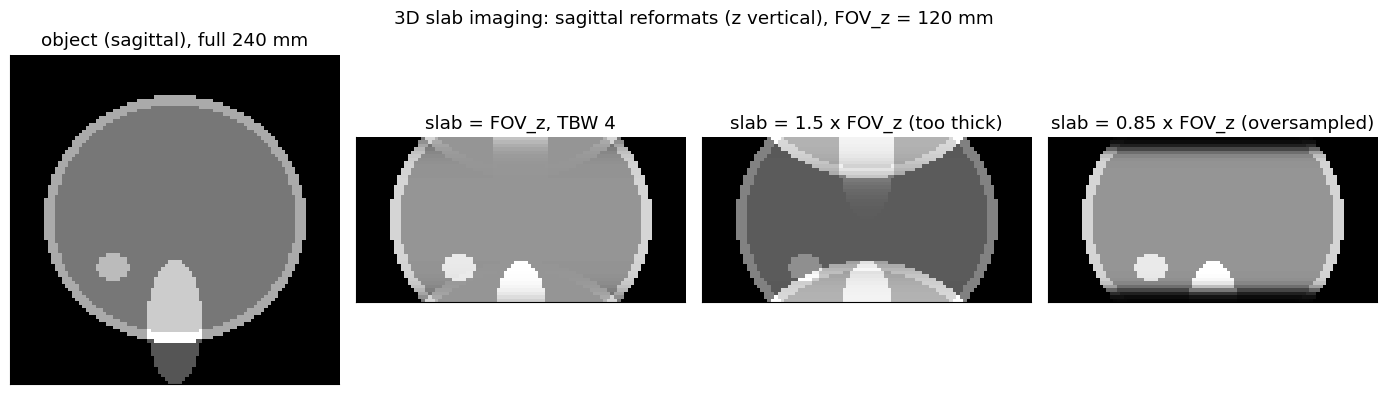

In [9]:
def head_phantom_3d(N=96, Nz=96, fov=(0.24, 0.24, 0.24)):
    """Simple 3D head phantom made of ellipsoids (values ~ proton density).

    Returns array (Nz, N, N) on a grid covering fov [m] in (z, y, x)."""
    z = (np.arange(Nz) - Nz / 2 + 0.5) / Nz * fov[2]
    y = (np.arange(N) - N / 2 + 0.5) / N * fov[1]
    x = (np.arange(N) - N / 2 + 0.5) / N * fov[0]
    Z, Y, X = np.meshgrid(z, y, x, indexing="ij")
    vol = np.zeros_like(X)
    ell = [  # value, (cx, cy, cz) [m], (ax, ay, az) semi-axes [m]
        (1.0, (0, 0, 0.00), (0.075, 0.095, 0.090)),      # scalp / skull-ish outer shell
        (-0.3, (0, 0, 0.00), (0.068, 0.088, 0.083)),     # brain (lower value inside)
        (-0.5, (0.012, 0.00, 0.01), (0.008, 0.030, 0.020)),  # ventricle right
        (-0.5, (-0.012, 0.00, 0.01), (0.008, 0.030, 0.020)), # ventricle left
        (0.4, (0, -0.045, -0.035), (0.015, 0.012, 0.010)),   # bright blob (e.g. cerebellum lesion)
        (0.3, (0.03, 0.03, 0.04), (0.006, 0.006, 0.006)),    # small round lesion
        (0.5, (0, -0.0, -0.075), (0.020, 0.020, 0.045)),     # neck / brainstem going down
    ]
    for v, (cx, cy, cz), (ax_, ay, az) in ell:
        vol[((X - cx) / ax_) ** 2 + ((Y - cy) / ay) ** 2 + ((Z - cz) / az) ** 2 <= 1] += v
    return vol

vol = head_phantom_3d()            # (z, y, x), z spans 240 mm, 2.5 mm voxels
Nz_ext = vol.shape[0]
z_ext = (np.arange(Nz_ext) - Nz_ext / 2 + 0.5) / Nz_ext * 0.24   # [m]
FOVz = 0.12                                                   # desired FOV_z [m] (half the grid)

def slab_profile(z, thickness, TBW):
    """Approximate small-tip slab profile: rect convolved with a smooth edge (width ~ thickness/TBW)."""
    edge = thickness / TBW
    return 0.5 * (np.tanh((z + thickness / 2) / (edge / 3)) - np.tanh((z - thickness / 2) / (edge / 3)))

def acquire_3d(vol, prof):
    """Weight by slab profile, FT along z, keep every 2nd kz (FOV_z halves -> aliasing), recon."""
    K = mt.fftc(vol * prof[:, None, None], axis=0)
    K_sub = K[::2]                               # Delta kz doubled -> FOV_z = 120 mm
    return np.abs(mt.ifftc(K_sub, axis=0))       # (Nz_ext/2, y, x)

cases = [("slab = FOV_z, TBW 4", slab_profile(z_ext, FOVz, 4)),
         ("slab = 1.5 x FOV_z (too thick)", slab_profile(z_ext, 1.5 * FOVz, 4)),
         ("slab = 0.85 x FOV_z (oversampled)", slab_profile(z_ext, 0.85 * FOVz, 8))]
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
mt.show_image(vol[::-1, :, vol.shape[2] // 2], ax=axes[0], title="object (sagittal), full 240 mm")
for ax, (name, prof) in zip(axes[1:], cases):
    rec = acquire_3d(vol, prof)
    mt.show_image(rec[::-1, :, rec.shape[2] // 2], ax=ax, title=name)   # [::-1]: head top up
plt.suptitle("3D slab imaging: sagittal reformats (z vertical), FOV_z = 120 mm"); plt.tight_layout(); plt.show()

*Left:* the whole object along $z$ (240 mm). *Second:* slab ≈ FOV: soft slab edges darken the top and bottom partitions and a little signal wraps. *Third:* a slab thicker than $FOV_z$: the neck and the top of the head excited outside the FOV wrap to the opposite side of the image. *Right:* a slab slightly thinner than the encoded FOV with a sharper pulse: no wrap. Scanners discard the darker edge partitions (oversampling).

> **⚠️ Common confusion:** In 3D imaging the slab-selection gradient does **not** determine the partition thickness; the $k_z$ encoding does. The slab pulse only limits *where* signal comes from, to prevent aliasing in $z$.

## 4. 2D multislice vs 3D imaging: the trade-offs

### 4.1 Coverage

* 2D multislice can have **gaps** in coverage when slices are not contiguous.
* 3D imaging provides **continuous coverage** without gaps, allowing more seamless evaluation of structures.

### 4.2 Contrast

* 2D multislice with interleaving efficiently supports **long TRs** for PD- and T2-weighted imaging, because any extra time within the TR is used to acquire other slices.
* 3D imaging needs a larger $N_{TR}$ to fill two phase-encoding dimensions. It is therefore much better suited for **short-TR** sequences: T1-weighted spoiled gradient echo, bSSFP, magnetization-prepared gradient echo (MPRAGE), and, with long echo trains, 3D fast spin echo.

### 4.3 Scan time

In 2D multislice, scan time depends on how many slices fit into one TR. The maximum number of slices is set by the time per slice (section 2.2):

$$N_{slices,max} = \left\lfloor\frac{TR}{T_{slice}}\right\rfloor .$$

Provided $N_{slices}\le N_{slices,max}$, the scan time for fully sampled Cartesian encoding is

$$T_{scan,2D} = TR\; N_{PE}\; N_{avg}.$$

In 3D imaging, the scan time depends on the size of both phase-encoding dimensions:

$$T_{scan,3D} = TR\; N_{PE,1}\; N_{PE,2}\; N_{avg}.$$

In words (both): one TR per phase-encode step (2D) or per pair of phase-encode steps (3D), times the number of averages $N_{avg}$ (= $NEX$).

### 4.4 SNR: where the $\sqrt{N_z}$ comes from

For fully sampled Cartesian encoding (see [Signal to Noise Ratio](../pass2_deep_dive/G2_Signal_to_Noise_Ratio.ipynb)):

$$SNR_{2D} \propto f_{seq,2D}\; V_{voxel}\; \sqrt{T_{read}\, N_{PE}\, N_{avg}}$$

$$SNR_{3D} \propto f_{seq,3D}\; V_{voxel}\; \sqrt{T_{read}\, N_{PE,1}\, N_{PE,2}\, N_{avg}}$$

In words: SNR is proportional to how much transverse magnetization the sequence produces ($f_{seq}$), to the amount of tissue in a voxel ($V_{voxel}$), and to the square root of the total time the ADC listens to signal that comes from that voxel ($T_{meas}$),

where $f_{seq}$ is the fraction of $M_0$ in the transverse plane at TE (from the signal equations, e.g. `mt.spin_echo_signal`), $V_{voxel}$ [m³] the voxel volume, $T_{read}$ [s] the readout duration per line, and $T_{meas} = T_{read}N_{PE}N_{avg}$ (2D) or $T_{read}N_{PE,1}N_{PE,2}N_{avg}$ (3D).

3D imaging has a **measurement-time advantage**: every single readout receives signal from the *entire* slab, so every voxel benefits from all $N_{PE,1}N_{PE,2}$ readouts. In 2D multislice, a readout of slice $i$ contains signal only from slice $i$.

<details><summary><b>📐 Derivation (optional): the √N_z gain, step by step</b></summary>

Consider just the $z$ direction, with $N_z$ voxels of signal $m_j$ ($j = 0,\dots,N_z-1$), and assume every measurement has independent complex Gaussian noise of standard deviation $\sigma_n$.

**2D multislice:** each slice $j$ is measured on its own: $s_j = m_j + n_j$. The estimate $\hat m_j = s_j$ has noise $\sigma_n$, so $SNR_{2D} = m_j/\sigma_n$. We used $N_z$ measurements in total.

**3D:** each measurement at partition-encode step $p$ contains all voxels with a phase ramp (the discrete signal equation):
$s_p = \sum_j m_j e^{-i2\pi pj/N_z} + n_p$, $p = 0,\dots,N_z-1$. Also $N_z$ measurements. The inverse DFT gives
$$\hat m_j = \frac{1}{N_z}\sum_p s_p e^{+i2\pi pj/N_z} = m_j + \underbrace{\frac{1}{N_z}\sum_p n_p e^{+i2\pi pj/N_z}}_{\text{noise}} .$$
The noise term is a sum of $N_z$ independent terms, each of std $\sigma_n/N_z$ (multiplying by a unit-magnitude phase doesn't change a circular Gaussian's std). Variances add: $\mathrm{Var} = N_z\,\sigma_n^2/N_z^2 = \sigma_n^2/N_z$, so the std is $\sigma_n/\sqrt{N_z}$ and

$$SNR_{3D} = \sqrt{N_z}\, \frac{m_j}{\sigma_n} = \sqrt{N_z}\, SNR_{2D}.$$

Same number of measurements, same voxel, but in 3D every measurement "sees" every voxel, so the noise averages down by $\sqrt{N_z}$. (The identical argument along $y$ is why SNR grows with $\sqrt{N_{PE}}$ in the first place.)

</details>

Let's check this with a Monte-Carlo simulation:

In [10]:
# Monte-Carlo check of SNR_3D / SNR_2D = sqrt(Nz) (same voxel, same number of measurements)
rng = np.random.default_rng(1)
sigma_n = 1.0
n_trials = 4000
for Nz in [4, 16, 64]:
    m = np.ones(Nz)                                     # true voxel signals along z
    # 2D: each slice measured separately -> estimate = measurement
    est_2d = m + sigma_n * (rng.standard_normal((n_trials, Nz)) + 1j * rng.standard_normal((n_trials, Nz))) / np.sqrt(2)
    # 3D: measure the DFT of the whole slab (unnormalized forward DFT), add the same noise per sample
    s_3d = np.fft.fft(m) + sigma_n * (rng.standard_normal((n_trials, Nz)) + 1j * rng.standard_normal((n_trials, Nz))) / np.sqrt(2)
    est_3d = np.fft.ifft(s_3d, axis=-1)                 # inverse DFT includes the 1/Nz
    snr2, snr3 = 1 / est_2d.std(axis=0).mean(), 1 / est_3d.std(axis=0).mean()
    print(f"Nz = {Nz:3d}: SNR_2D = {snr2:5.2f}, SNR_3D = {snr3:5.2f}, ratio = {snr3/snr2:5.2f}, sqrt(Nz) = {np.sqrt(Nz):5.2f}")

Nz =   4: SNR_2D =  1.01, SNR_3D =  2.00, ratio =  1.98, sqrt(Nz) =  2.00
Nz =  16: SNR_2D =  1.00, SNR_3D =  4.01, ratio =  4.01, sqrt(Nz) =  4.00
Nz =  64: SNR_2D =  1.00, SNR_3D =  8.01, ratio =  8.00, sqrt(Nz) =  8.00


The ratio matches $\sqrt{N_z}$.

However, part of this advantage is offset by the **sequence factor** $f_{seq}$: interleaved 2D multislice can use a long TR (more T1 recovery, $f_{seq}$ large) at no time cost, while 3D needs a short TR (small $f_{seq}$). The fair comparison is **at equal scan time**. Then something perhaps surprising happens:

* 2D, all slices in one TR: $T_{scan} = TR_{2D}N_y$. Each voxel's slice is read $N_y$ times: $T_{meas} = N_yT_{read}$.
* 3D in the same time: $TR_{3D} = TR_{2D}/N_z$. Each voxel is read $N_yN_z$ times: $T_{meas} = N_yN_zT_{read}$.

So at equal scan time 3D still has $\sqrt{N_z}$ more measurement time per voxel, but with a TR that is $N_z$ times shorter, so less signal per excitation. Which wins depends on the contrast. Let's compare a 2D T1-weighted spin echo with a 3D spoiled gradient echo at the Ernst angle:

In [11]:
# SNR comparison 2D SE multislice vs 3D spoiled GRE at matched voxel size (relative units)
T1_wm, T2_wm, T2s_wm = 0.6, 0.08, 0.05      # white matter at 1.5 T [s]
Ny, Nz, T_read = 256, 128, 4e-3              # Nz = slices (2D) or partitions (3D)

# 2D T1w spin echo: TR = 500 ms, TE = 12 ms; Nz slices must fit in TR
TR2, TE2 = 0.5, 12e-3
f2 = mt.spin_echo_signal(TE2, TR2, T1_wm, T2_wm)
n_acq = int(np.ceil(Nz / (TR2 // 0.018)))         # packages needed (T_slice = 18 ms)
T2d = TR2 * Ny * n_acq
snr2 = f2 * np.sqrt(Ny * T_read)

# 3D spoiled GRE: TR = 8 ms, TE = 3 ms, flip = Ernst angle
TR3, TE3 = 8e-3, 3e-3
th = mt.ernst_angle(TR3, T1_wm)
f3 = mt.spoiled_gre_signal(th, TE3, TR3, T1_wm, T2s_wm)
T3d = TR3 * Ny * Nz
snr3 = f3 * np.sqrt(Ny * Nz * T_read)

print(f"2D SE : f_seq = {f2:.3f}, packages = {n_acq}, T_scan = {T2d/60:5.1f} min, SNR ∝ {snr2:.3f}, SNR/sqrt(T_scan) ∝ {snr2/np.sqrt(T2d):.4f}")
print(f"3D GRE: f_seq = {f3:.3f} (Ernst {np.degrees(th):.0f}°), T_scan = {T3d/60:5.1f} min, SNR ∝ {snr3:.3f}, SNR/sqrt(T_scan) ∝ {snr3/np.sqrt(T3d):.4f}")

2D SE : f_seq = 0.487, packages = 5, T_scan =  10.7 min, SNR ∝ 0.492, SNR/sqrt(T_scan) ∝ 0.0195
3D GRE: f_seq = 0.077 (Ernst 9°), T_scan =   4.4 min, SNR ∝ 0.880, SNR/sqrt(T_scan) ∝ 0.0544


The 3D gradient echo has a much smaller $f_{seq}$ (≈ 0.08 vs ≈ 0.5), but the $\sqrt{N_z}=\sqrt{128}\approx 11$ gain more than compensates, and it doesn't need 5 slice packages: about 2.8× higher SNR efficiency. For 128 contiguous thin (1–2 mm) slices, 3D is the clear winner. For 20 thick slices with long-TR T2 weighting, 2D multislice usually wins. The **SNR efficiency** $SNR/\sqrt{T_{scan}}$ is the fair figure of merit.

### 4.5 Isotropic resolution and reformatting

3D imaging easily achieves **isotropic resolution** ($\delta_x=\delta_y=\delta_z$, e.g. 1 mm³ voxels). An isotropic volume can be **reformatted** (re-sliced) after the scan into any plane (axial, sagittal, coronal or oblique, even curved planes following a vessel or the spine) with the same quality. 2D slices are usually thick ($\delta_z$ = 3–5 mm) compared with in-plane pixels (0.5–1 mm). Reformatting them gives blocky, smeared images (**partial-volume** effects: one thick voxel averages different tissues).

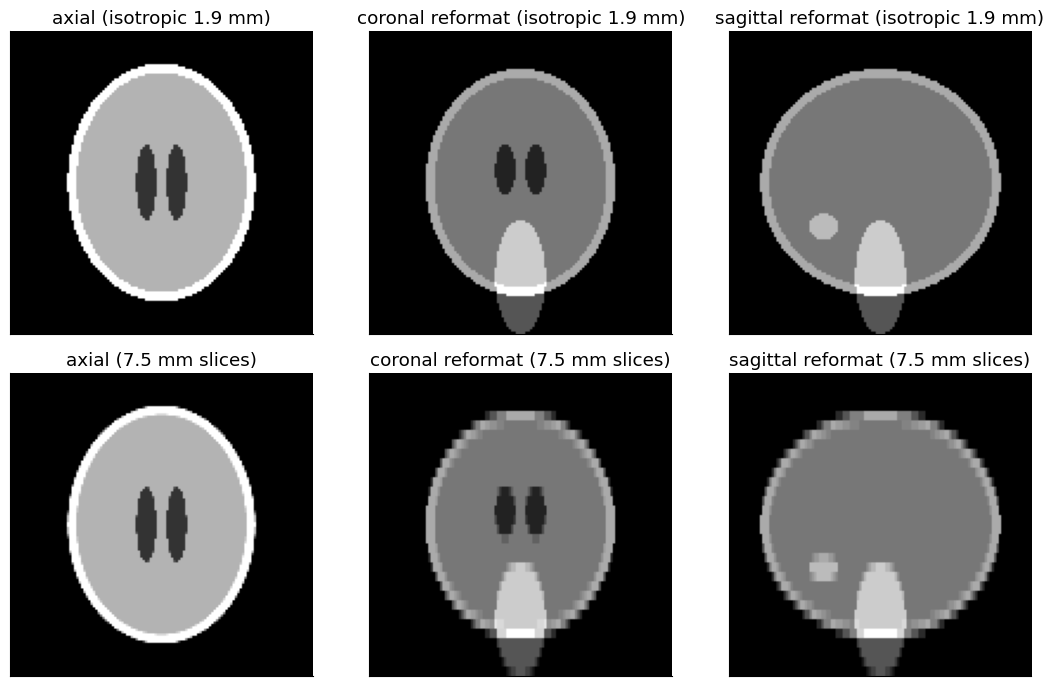

In [12]:
# Reformatting: isotropic 3D vs thick 2D slices (same phantom, coronal/sagittal views)
vol = head_phantom_3d(N=128, Nz=128)          # 1.875 mm isotropic voxels over 240 mm
thick = 4                                     # thick slices: average 4 partitions (7.5 mm)
vol_thick = vol.reshape(-1, thick, *vol.shape[1:]).mean(axis=1)
vol_thick_up = np.repeat(vol_thick, thick, axis=0)   # display on the fine grid (what a viewer does)

c = vol.shape[1] // 2
fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for row, (v, lab) in enumerate([(vol, "isotropic 1.9 mm"), (vol_thick_up, "7.5 mm slices")]):
    mt.show_image(v[vol.shape[0] // 2 + 6], ax=axes[row, 0], title=f"axial ({lab})")
    mt.show_image(v[::-1, c, :], ax=axes[row, 1], title=f"coronal reformat ({lab})")
    mt.show_image(v[::-1, :, c], ax=axes[row, 2], title=f"sagittal reformat ({lab})")
plt.tight_layout(); plt.show()

The axial images look similar (that's the plane of the thick slices), but the coronal and sagittal reformats of thick slices are staircased: curved edges become steps, and the small round lesion and the top of the ventricles are smeared along $z$ through partial volume.

> **🔧 Engineering reality:** 3D data sets are large. A 256 × 256 × 256 volume from a 32-channel coil is $256^3 \times 32 \approx 5.4\times10^8$ complex samples, about 4.3 GB at 8 bytes per sample (single precision), before averaging or multiple contrasts. Reconstruction (3D FFTs, coil combination, iterative methods in [H3](../pass2_deep_dive/H3_Accelerated_Imaging_Methods.ipynb)) needs a powerful reconstruction computer with lots of RAM, often with GPUs. Also, the second phase-encoding gradient on $z$ must be very reproducible from TR to TR; eddy currents or vibration that differ between $k_z$ steps cause artifacts along $z$.

### 4.6 Summary table

| Aspect | 2D multislice | 3D |
|---|---|---|
| $z$ localization | selective RF pulse per slice | phase encoding along $z$ (slab RF) |
| Slice/partition profile | set by RF pulse (soft edges, cross-talk) | set by Fourier encoding (sinc PSF), no cross-talk |
| Thinnest practical slices | ~2 mm | 0.5–1 mm |
| Coverage | gaps possible | contiguous |
| Preferred TR | long (PD, T2w, FLAIR) via interleaving | short (T1w GRE, bSSFP, MPRAGE) or long echo trains (3D FSE) |
| Scan time | $TR\,N_{PE}\,NEX\,N_{acq}$ | $TR\,N_{y}\,N_z\,NEX$ |
| SNR | $\propto\sqrt{N_{PE}}$ per slice | extra $\sqrt{N_z}$ |
| Reformatting | poor (anisotropic) | excellent if isotropic |
| Motion | corrupts only slices acquired at that moment | corrupts the whole volume |
| Aliasing in $z$ | none (slices are excited separately) | yes, needs slab profile + oversampling |
| Inflow of fresh blood | strong (thin slice, many fresh spins) | weaker (thick slab, spins saturated) |

The last row is the basis of 2D "time-of-flight" angiography, see [In Vivo Contrast Mechanisms](../pass2_deep_dive/D2_In_Vivo_Contrast_Mechanisms.ipynb).

## Try it yourself (interactive)

Change TR, the time per slice and the number of requested slices and watch the scan time. (Widgets don't run in a static view; the cell above already gives a static version.)

In [13]:
try:
    from ipywidgets import interact, FloatSlider, IntSlider
    def scan_time(TR_ms=500.0, T_slice_ms=20.0, n_slices=30, N_PE=256):
        n_max = max(int(TR_ms // T_slice_ms), 1)
        n_acq = int(np.ceil(n_slices / n_max))
        T = TR_ms * 1e-3 * N_PE * n_acq
        print(f"N_max = {n_max}, packages = {n_acq}, T_scan = {T:.0f} s = {T/60:.1f} min")
    interact(scan_time, TR_ms=FloatSlider(min=5, max=5000, step=5, value=500),
             T_slice_ms=FloatSlider(min=5, max=150, step=1, value=20),
             n_slices=IntSlider(min=1, max=200, value=30), N_PE=IntSlider(min=64, max=512, step=32, value=256))
except ImportError:
    print("ipywidgets not available")

interactive(children=(FloatSlider(value=500.0, description='TR_ms', max=5000.0, min=5.0, step=5.0), FloatSlide…

## Key takeaways

* **2D multislice** selects each slice with an RF frequency offset $f_{off}=\bar\gamma G_{z,SS}z_{off}$ and **interleaves** slices within each TR. Up to $\lfloor TR/T_{slice}\rfloor$ slices are "free".
* Long TR (PD/T2w) makes interleaving very efficient; very short TR (fast GRE) leaves room for only one slice per TR.
* **Cross-talk** from imperfect slice profiles reduces signal and alters contrast; reduce it with higher-TBW pulses, slice gaps, and interleaved slice order.
* **3D imaging** phase-encodes along $z$ too: $T_{scan}=TR\,N_yN_z\,NEX$, so it needs short TR (or long echo trains). The slab pulse only prevents $z$ aliasing; partitions are defined by $k_z$ encoding.
* 3D has an SNR advantage of $\sqrt{N_z}$ from measurement time (every readout sees the whole slab), partly offset by lower $f_{seq}$ at short TR. Compare SNR efficiency at equal scan time.
* 3D gives contiguous, thin, often **isotropic** voxels that can be reformatted in any plane; 2D thick slices give partial-volume and staircase artifacts in reformats.

## Check your understanding

1. A 2D spin-echo protocol has TR = 600 ms and needs 22 ms per slice. How many slices fit into one TR, and how long does a 256-line scan with 40 slices take (NEX = 1)?

<details><summary>Answer</summary>

$N_{slices,max}=\lfloor 600/22\rfloor = 27$. 40 slices need $N_{acq}=\lceil 40/27\rceil = 2$ packages, so $T_{scan} = 0.6\,\text{s}\times256\times2 = 307$ s ≈ 5.1 min. With 27 slices or fewer it would be 2.6 min.

</details>

2. Why does a contiguous (0 % gap) 2D stack acquired in sequential order show reduced signal, and name three ways to reduce the effect.

<details><summary>Answer</summary>

Real slice profiles have soft edges, so each pulse partially saturates the edges of its neighbours (cross-talk). The edge spins have less $M_z$ when their own pulse arrives. Fixes: higher-TBW (sharper) RF pulses, slice gaps (10–30 %), interleaved slice order (neighbours ~TR/2 apart) or splitting odd/even slices into separate packages, or switching to 3D.

</details>

3. A 3D acquisition has $N_y=192$, $N_z=64$, TR = 10 ms. What is the scan time? What would it be with a spin-echo TR of 2 s, and what does this tell you?

<details><summary>Answer</summary>

$0.01\times192\times64 = 123$ s ≈ 2 min. With TR = 2 s: 24 576 s ≈ 6.8 h. Basic 3D imaging needs short-TR sequences (gradient echo); long-TR contrasts need echo trains (3D FSE) and/or acceleration to be done in 3D.

</details>

4. Compare a 2D multislice and a 3D acquisition with identical voxel size, the same $N_y$, $T_{read}$, NEX and $f_{seq}$, and $N_z = 100$. What is the SNR ratio, and why?

<details><summary>Answer</summary>

$SNR_{3D}/SNR_{2D}=\sqrt{N_z}=10$. Every 3D readout contains signal from all partitions, so each voxel's estimate averages $N_z$ times more independent noise samples (the inverse FT along $k_z$ averages them). In practice $f_{seq}$ is usually smaller in 3D because of the short TR, which eats part of this gain.

</details>

5. In a 3D acquisition the top and bottom partitions show a faint copy of the neck. What happened, and how do you fix it?

<details><summary>Answer</summary>

Aliasing (wrap-around) in the $z$ phase-encoding direction: the slab pulse excited tissue outside $FOV_z$ (soft slab edges or slab thicker than $FOV_z$). Fixes: a sharper and/or slightly thinner slab pulse, slice (partition) oversampling with the edge partitions discarded, or a larger $FOV_z$.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "Volumetric Imaging".
Changes: added symbol table, slice-offset and interleaving numerics, Bloch-simulated slice profiles and a cross-talk model, slice ordering, 3D k-space and FOV/resolution in $z$, slab aliasing simulation, a step-by-step derivation and Monte-Carlo check of the $\sqrt{N_z}$ SNR gain, an equal-time SNR-efficiency comparison, reformatting/isotropic resolution demo, an engineering note and a comparison table. The original's $T_{active}$ is called $T_{slice}$ here, and the floor operation in $N_{slices,max}$ is made explicit.*